In [2]:
# 셀 1: 패키지 설치
!pip install -q ddgs requests pillow matplotlib

/shared/home/mai/anaconda3/envs/butam/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 28338.93it/s]


Regular glasses: 5/5장 통과
Smart glasses: 5/5장 통과


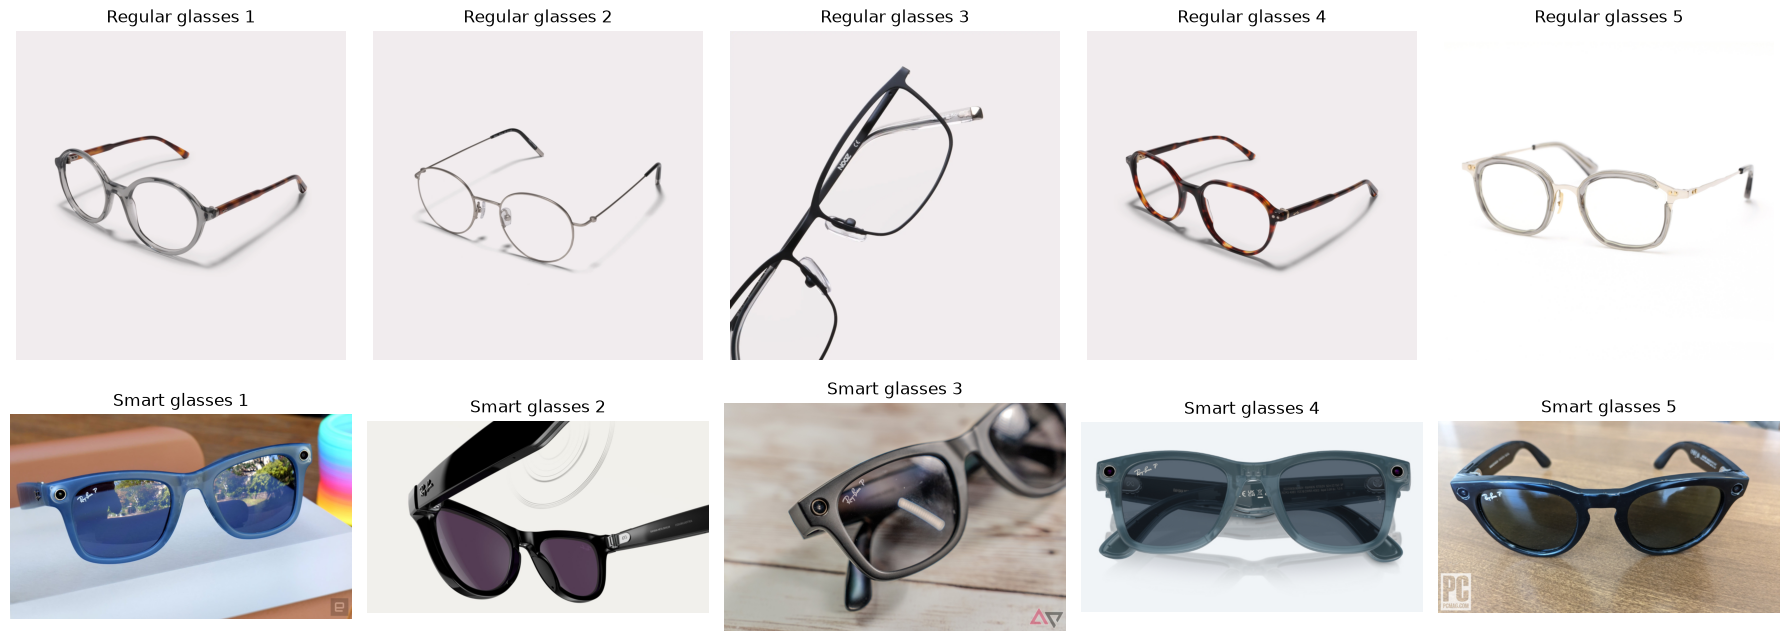

In [8]:
# 셀 2
from io import BytesIO
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
from ddgs import DDGS
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(model_id)
model = CLIPModel.from_pretrained(model_id).to(device).eval()

# 첫 문장만 채택하고 나머지에 가까운 이미지는 제외
descriptions = [
    "A product photo of exactly one complete pair of eyeglasses, shown once.",
    "A photo of multiple pairs of eyeglasses together.",
    "A collage showing glasses from multiple angles in separate panels.",
    "An advertisement with diagrams, text, and multiple product views.",
    "A close-up showing only part of eyeglasses.",
    "A person wearing glasses.",
    "A product kit showing glasses with cases and accessories.",
]

@torch.inference_mode()
def keep_image(image):
    inputs = processor(
        text=descriptions, images=image,
        return_tensors="pt", padding=True,
    ).to(device)
    scores = model(**inputs).logits_per_image[0]
    return scores.argmax().item() == 0

queries = [
    ("Regular glasses", "single pair prescription eyeglasses product -collage -collection"),
    ("Smart glasses", "Ray-Ban Meta smart glasses single product -collage"),
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for row, (label, query) in enumerate(queries):
    for ax in axes[row]:
        ax.axis("off")

    count = 0
    seen = set()

    for result in DDGS().images(query, max_results=100):
        url = result.get("image")
        if not url or url in seen:
            continue
        seen.add(url)

        try:
            response = requests.get(
                url, timeout=10,
                headers={"User-Agent": "Mozilla/5.0"},
            )
            response.raise_for_status()
            image = Image.open(BytesIO(response.content)).convert("RGB")
            image.thumbnail((800, 800))
        except (requests.RequestException, OSError, ValueError):
            continue

        # 여러 개·합성 이미지이면 표시하지 않고 다음 후보로
        if not keep_image(image):
            continue

        axes[row, count].imshow(image)
        axes[row, count].set_title(f"{label} {count + 1}")
        count += 1

        if count == 5:
            break

    print(f"{label}: {count}/5장 통과")

plt.tight_layout()
plt.show()